# LDA y GenAI

Encontrar los topicos de noticias Argentinas mediante el algoritmo de LDA y la API de chatgpt.

In [1]:
import os
import glob
import nltk
import string
import collections
import unicodedata


import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt


from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation


from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/jmanuelc87/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/jmanuelc87/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/jmanuelc87/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/jmanuelc87/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [2]:
files = glob.glob("../data/noticias-argentinas/**/*.txt", recursive=True)

In [3]:
def read(path):
    with open(path, "r") as blob:
        return blob.read()

In [4]:
df = pd.DataFrame(data=[read(file) for file in files], columns=["text"])

df.head(), df.count()

(                                                text
 0  Buenos días, buenos días a todos, la verdad es...
 1  Buenos días, buenos días, buenos días. Qué lin...
 2  Buen día, buen día a todos. Qué lindo comenzar...
 3  Buen día, buen día, una alegría estar hoy acá ...
 4  Buenas tardes, queridos cordobeses: una alegrí...,
 text    1328
 dtype: int64)

In [5]:
spanish_stopwords = set(stopwords.words("spanish"))


wnl = WordNetLemmatizer()


def eliminar_acentos(texto):
    texto_normalizado = unicodedata.normalize("NFD", texto)
    return "".join(c for c in texto_normalizado if unicodedata.category(c) != "Mn")


def explode(sentence):
    texto_normalizado = eliminar_acentos(sentence)
    words = word_tokenize(texto_normalizado)
    filtered = [w for w in words if w not in spanish_stopwords]
    stems = [wnl.lemmatize(w) for w in filtered]
    stems_no_punct = [w for w in stems if w not in string.punctuation]

    return " ".join(stems_no_punct)

In [6]:
df_sent = df["text"].apply(explode)

df_sent.head()

0    Buenos dia buenos dia verdad toco dia excepcio...
1    Buenos dia buenos dia buenos dia Que lindo aca...
2    Buen dia buen dia Que lindo comenzar semana ro...
3    Buen dia buen dia alegria hoy aca Gobernadora ...
4    Buenas tardes queridos cordobeses alegria nuev...
Name: text, dtype: str

In [7]:
dictionary = collections.Counter()

for r in df_sent:
    dictionary.update(r.split())


updated = []

for r in df_sent:
    updated.append([w for w in r.split() if 10000 > dictionary[w] > 50])


df_send = pd.DataFrame([" ".join(u) for u in updated])


df_sent.head()

0    Buenos dia buenos dia verdad toco dia excepcio...
1    Buenos dia buenos dia buenos dia Que lindo aca...
2    Buen dia buen dia Que lindo comenzar semana ro...
3    Buen dia buen dia alegria hoy aca Gobernadora ...
4    Buenas tardes queridos cordobeses alegria nuev...
Name: text, dtype: str

In [8]:
vec = TfidfVectorizer()

df_vectorized = vec.fit_transform(df_sent)

tfidf = pd.DataFrame(df_vectorized.todense(), columns=vec.get_feature_names_out())

tfidf.iloc[10:30, 2000:2010]

,albergue,albergues,albert,alberti,alberto,albino,albores,alborotado,alca,alcalde
10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
17,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
18,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000


In [9]:
N = 30

log = {}

for i in range(1, N):
    lda = LatentDirichletAllocation(
        n_components=i,
        learning_method="online",
        learning_offset=50.0,
    )

    Latent = lda.fit_transform(tfidf)

    log[i] = {"perplexity": lda.perplexity(Latent), "model": lda}

In [10]:
best = sorted(log.items(), key=lambda x: x[1]["perplexity"], reverse=False)[0]

best

(2,
 {'perplexity': np.float64(6807899.910157226),
  'model': LatentDirichletAllocation(learning_method='online', learning_offset=50.0,
                            n_components=2)})

In [11]:
def plot_top_words(model, feature_names, components, n_top_words, title):
    fig, axes = plt.subplots(2, (components // 2) + 1, figsize=(30, 15), sharex=False)
    axes = axes.flatten()
    topics = {}
    for topic_idx, topic in enumerate(model.components_):
        top_features_ind = topic.argsort()[-n_top_words:]
        top_features = feature_names[top_features_ind]
        weights = topic[top_features_ind]
        topics[topic_idx] = top_features

        ax = axes[topic_idx]
        ax.barh(top_features, weights, height=0.7)
        ax.set_title(f"Topic {topic_idx + 1}", fontdict={"fontsize": 30})
        ax.tick_params(axis="both", which="major", labelsize=20)
        for i in "top right left".split():
            ax.spines[i].set_visible(False)
        fig.suptitle(title, fontsize=40)

    plt.subplots_adjust(top=0.90, bottom=0.05, wspace=0.90, hspace=0.3)
    plt.show()

    return topics

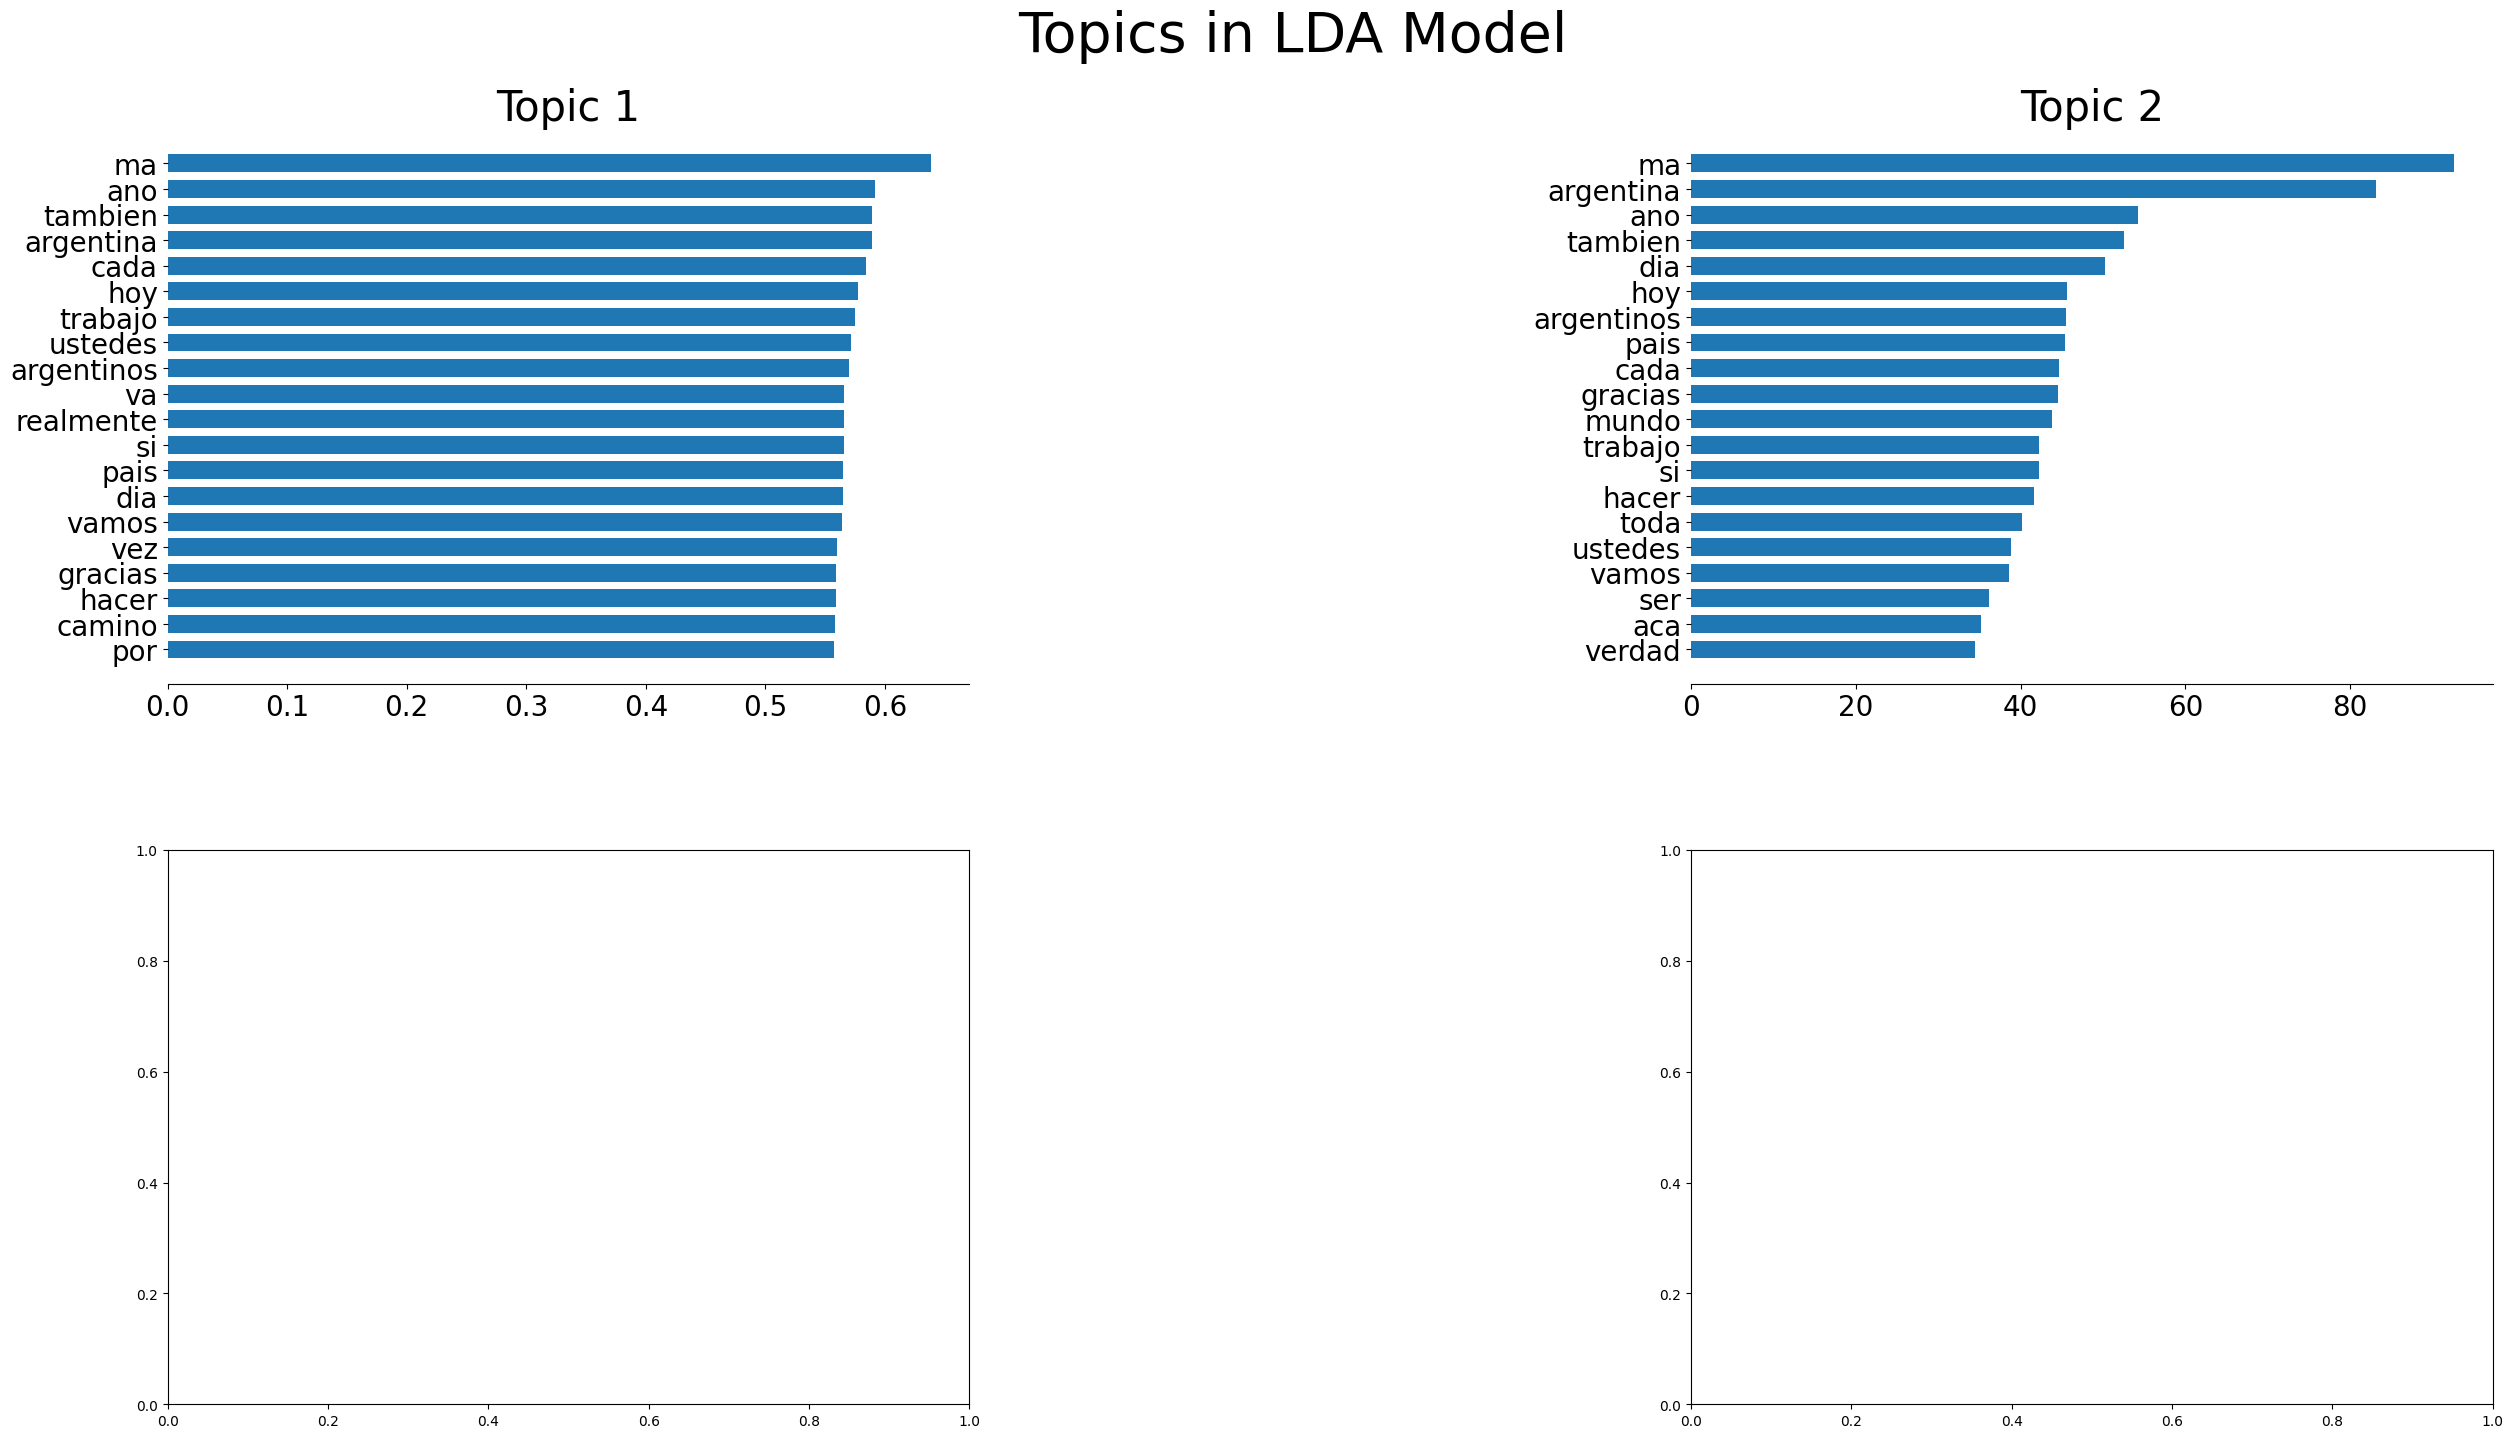

In [12]:
topics = plot_top_words(best[1]["model"], vec.get_feature_names_out(),  best[0], 20, "Topics in LDA Model")